# Beam-α bootstrap (per-band `beam_scale`)

Estimate a restoring-beam scale **α** for every OVRO-LWA subband so Total fluxes
are photometrically consistent, then feed the mapping into a re-run of
`ovro_lwa_healpix_tile_detect.ipynb`.

**Required prior:** `Total_flux_*` already embeds the detect-time beam scale.
You must set `BEAM_SCALE_USED` to that value (`1.0` if the tree was detected
unscaled). The VLSSR step estimates a **correction**; absolute α is the product:

`α_true = BEAM_SCALE_USED × √(median Total_anchor / Peak_VLSSR)`

Running the anchor without the correct `BEAM_SCALE_USED` biases every band.

**Method**

1. **Anchor at 73 MHz** against unique VLSSR Peak (74 MHz) using the product above.
2. **Neighbor steps** on unconfused unique pairs (`n_assoc==1`, `n_confused==1`):
   Peak removes spectral slope via
   `(T_hi/T_lo)/(P_hi/P_lo) ≈ (α_lo/α_hi)²`.
3. Plot VLSSR Total–Peak and neighboring-band Total–Total flux–flux (unconfused unique).
4. Write `{CATALOG_DIR}/beam_alpha_by_band.parquet` and `{CATALOG_DIR}/beam_scale.json`
   (BEAM_SCALE mapping + VLSSR anchor metadata) and print a dict for paste/load.

**Prerequisites:** fusion (or spectral) metacatalog with LWA `Total_flux_*` /
`Peak_flux_*` / `n_assoc_*` / `n_confused_*`, plus unique VLSSR attach columns
(`Peak_flux_VLSSR`, `n_assoc_VLSSR`) — typically after `radio_crossmatch.ipynb`.


In [12]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from lwa_catalog import CatalogLayout, read_metacatalog
from lwa_catalog.analyze import (
    CORE_CLEAN_EXCLUDE_MASK,
    BeamAlphaBootstrapConfig,
    bootstrap_beam_alpha,
    load_beam_alpha_mapping,
    summarize_beam_alpha_bootstrap,
    write_beam_alpha_table,
)

# --- operator config ---
CATALOG_DIR = Path("/fast/claw/metacatalog_healpix_IdTR-0.75s_subband2")
# REQUIRED: detect-time beam_scale that built Total_flux_* on this tree.
# α_true = BEAM_SCALE_USED × √(med Total/VLSSR). Use 1.0 if detect was unscaled.
# Examples: subband3 / library default → 1.0; subband2 (BEAM_SCALE=1.2) → 1.2.
BEAM_SCALE_USED: float | None = 1.0
ANCHOR_BAND = "73MHz"
# Prefer spectral product when VLSSR is already attached; else fusion (will fail
# without Peak_flux_VLSSR).
PREFER_SPECTRAL = True
QUALITY_FLAG_MASK = CORE_CLEAN_EXCLUDE_MASK  # None to skip quality filter on fusion
WRITE_OUTPUT = True

if BEAM_SCALE_USED is None:
    raise ValueError(
        "Set BEAM_SCALE_USED to the detect-time α used when this metacatalog "
        "was built (1.0 if unscaled). Totals already embed that scale; "
        "α_true = BEAM_SCALE_USED × √(med Total_anchor / Peak_VLSSR)."
    )
BEAM_SCALE_USED = float(BEAM_SCALE_USED)
if not np.isfinite(BEAM_SCALE_USED) or BEAM_SCALE_USED <= 0.0:
    raise ValueError(
        f"BEAM_SCALE_USED must be finite and > 0; got {BEAM_SCALE_USED!r}"
    )

layout = CatalogLayout(CATALOG_DIR)
INPUT_PATH = (
    layout.metacatalog_spectral()
    if PREFER_SPECTRAL and layout.metacatalog_spectral().is_file()
    else layout.metacatalog()
)
OUTPUT_PATH = layout.beam_alpha_by_band()

print("CATALOG_DIR =", layout.root.resolve())
print("INPUT_PATH =", INPUT_PATH.resolve(), "exists:", INPUT_PATH.is_file())
print("OUTPUT_PATH =", OUTPUT_PATH.resolve())
print("BEAM_SCALE_USED =", BEAM_SCALE_USED, "(required prior for VLSSR anchor)")
print("ANCHOR_BAND =", ANCHOR_BAND)
print("PREFER_SPECTRAL =", PREFER_SPECTRAL)
print("WRITE_OUTPUT =", WRITE_OUTPUT)
print(
    "α_true = BEAM_SCALE_USED × correction, "
    "correction = √(median Total_anchor / Peak_VLSSR)"
)


CATALOG_DIR = /fast/claw/metacatalog_healpix_IdTR-0.75s_subband2
INPUT_PATH = /fast/claw/metacatalog_healpix_IdTR-0.75s_subband2/metacatalog_spectral.parquet exists: True
OUTPUT_PATH = /fast/claw/metacatalog_healpix_IdTR-0.75s_subband2/beam_alpha_by_band.parquet
BEAM_SCALE_USED = 1.0 (required prior for VLSSR anchor)
ANCHOR_BAND = 73MHz
PREFER_SPECTRAL = True
WRITE_OUTPUT = True
α_true = BEAM_SCALE_USED × correction, correction = √(median Total_anchor / Peak_VLSSR)


## Load metacatalog + bootstrap α


In [13]:
# Spectral product is already quality-filtered at write time.
quality_mask = None if INPUT_PATH == layout.metacatalog_spectral() else QUALITY_FLAG_MASK
meta = read_metacatalog(INPUT_PATH, quality_mask=quality_mask)
print(f"rows: {len(meta):,}  from {INPUT_PATH.name}")
print(f"Peak_flux_VLSSR present: {'Peak_flux_VLSSR' in meta.columns}")
print(f"n_assoc_VLSSR present: {'n_assoc_VLSSR' in meta.columns}")

config = BeamAlphaBootstrapConfig(
    anchor_band=ANCHOR_BAND,
    beam_scale_used=BEAM_SCALE_USED,
)
result = bootstrap_beam_alpha(meta, config=config)
print(summarize_beam_alpha_bootstrap(result))
print(
    f"product check: {result.beam_scale_used:g} × {result.alpha_correction:.6f} "
    f"= {result.beam_scale_used * result.alpha_correction:.6f} "
    f"(α_{ANCHOR_BAND}={result.alpha_anchor:.6f})"
)
if result.warnings:
    for w in result.warnings:
        print("warning:", w)

print("\nNeighbor steps:")
print(result.steps.to_string(index=False))
print("\nPer-band α (absolute = BEAM_SCALE_USED × VLSSR correction × neighbor walk):")
print(result.by_band.to_string(index=False))

beam_alpha_mapping = result.as_mapping()
print("\n# Paste into ovro_lwa_healpix_tile_detect.ipynb as BEAM_SCALE = {...}")
print("BEAM_SCALE = {")
for band, alpha in beam_alpha_mapping.items():
    print(f"    {band!r}: {alpha:.6g},")
print("}")


rows: 160,117  from metacatalog_spectral.parquet
Peak_flux_VLSSR present: True
n_assoc_VLSSR present: True
anchor 73MHz: α_true=1.0987  = beam_scale_used=1 × correction=1.0987  (√(med Total/VLSSR=1.2072), n_unique=13,271)
α range 1.0755 … 1.1294  (spread 1.050×; median 1.1089)
product check: 1 × 1.098744 = 1.098744 (α_73MHz=1.098744)

Neighbor steps:
band_lo band_hi direction      n  median_T_hi_over_lo  median_P_hi_over_lo  alpha_hi_over_lo  alpha_lo  alpha_hi
  73MHz   78MHz        up 115116             0.947398             0.926183          0.988740  1.098744  1.086372
  78MHz   82MHz        up 114696             0.957193             0.938209          0.990034  1.086372  1.075545
  69MHz   73MHz      down 106830             0.947267             0.922515          0.986849  1.113386  1.098744
  64MHz   69MHz      down  99567             0.930675             0.922741          0.995728  1.118162  1.113386
  59MHz   64MHz      down  86529             0.939495             0.982456        

## Neighbor Total flux–flux + α plot + write Parquet


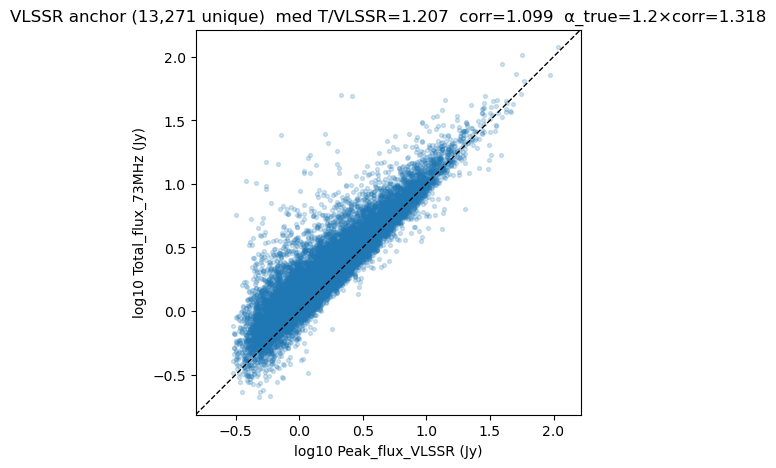

LWA bands with Total_flux (15): ['18MHz', '23MHz', '27MHz', '32MHz', '36MHz', '41MHz', '46MHz', '50MHz', '55MHz', '59MHz', '64MHz', '69MHz', '73MHz', '78MHz', '82MHz']
Neighbor pairs: 14


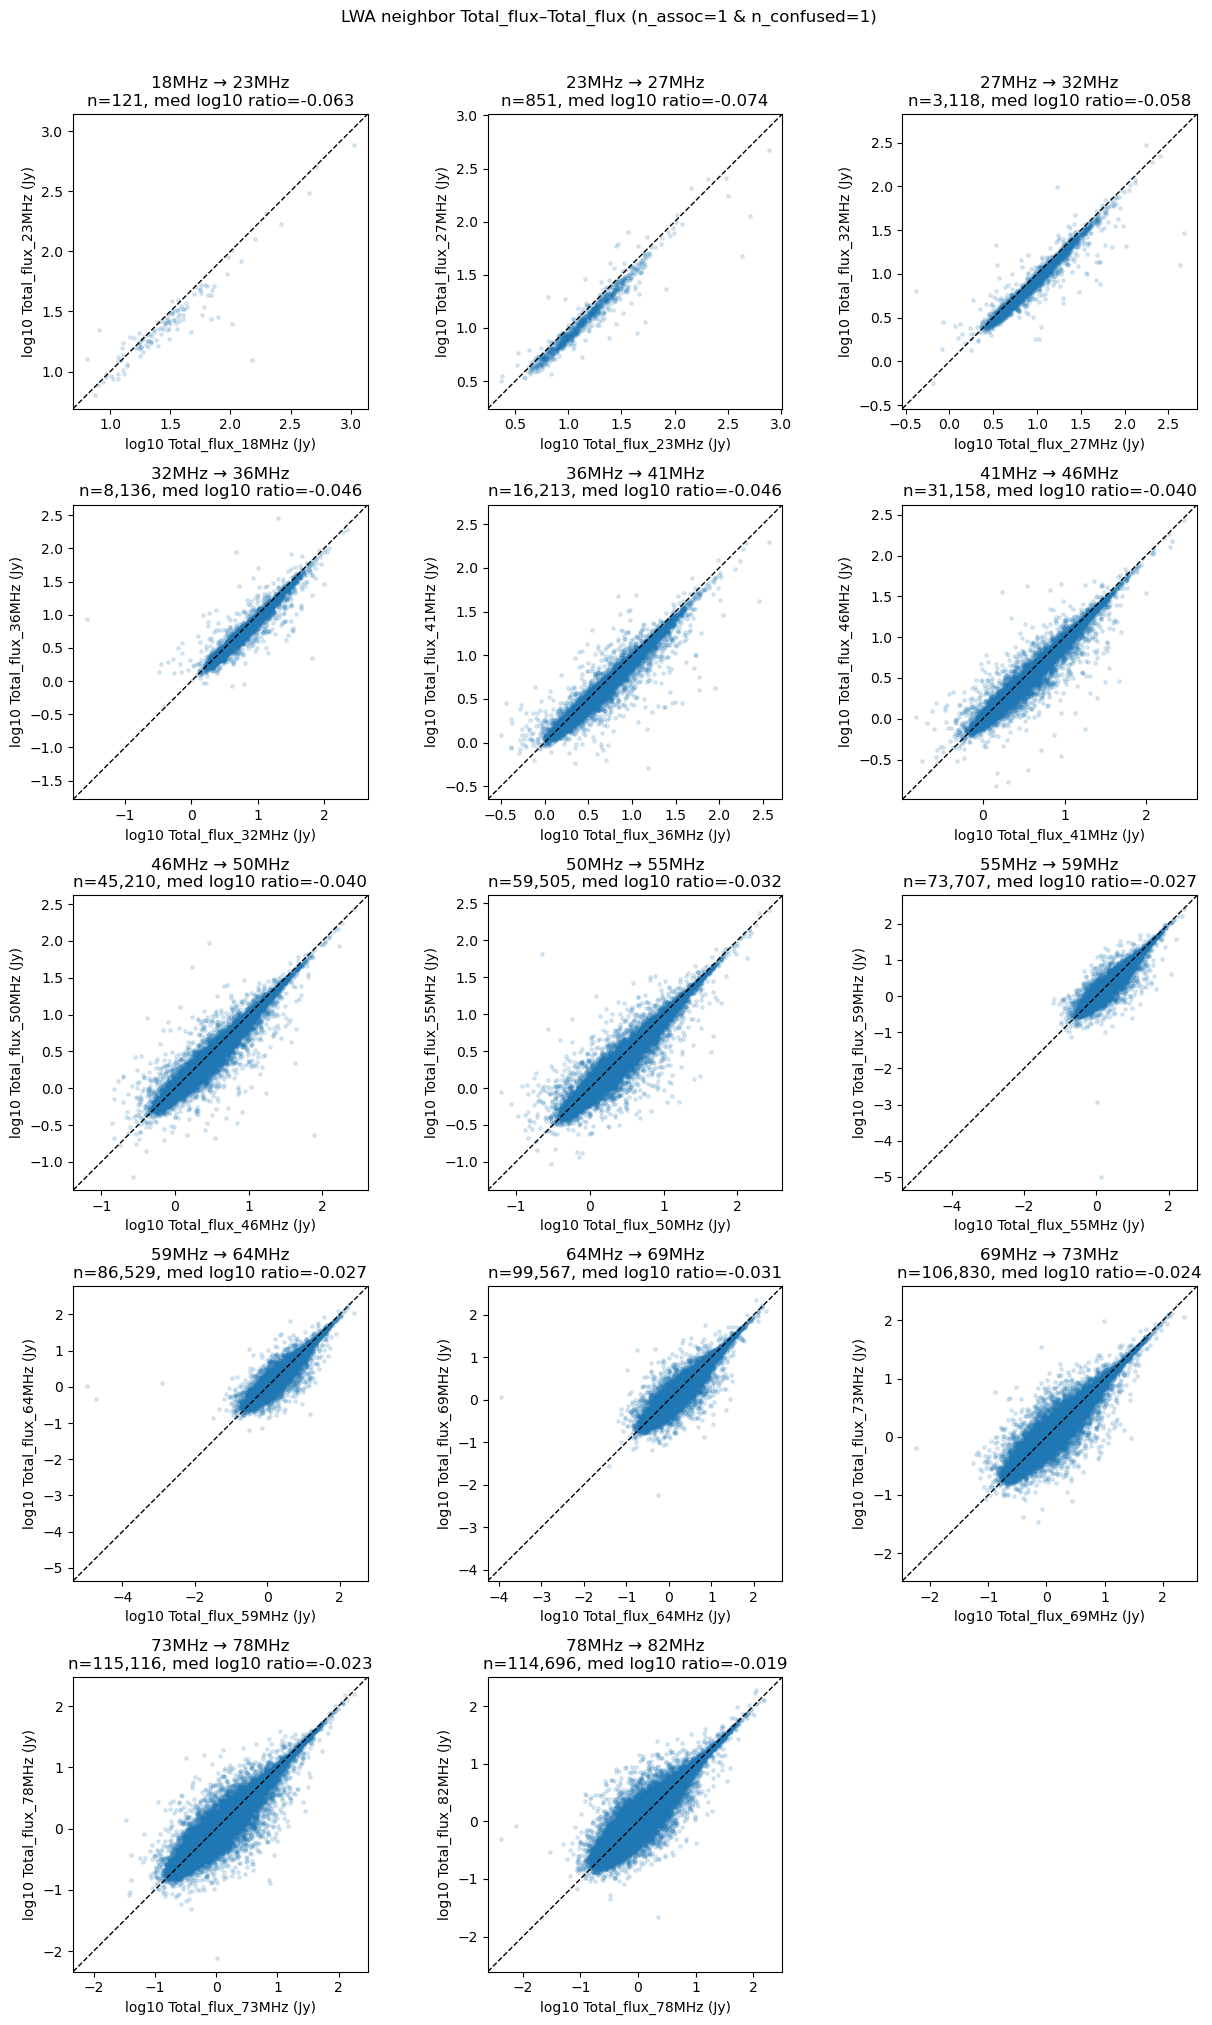

band_lo band_hi  n_unconfused_unique  median_T_hi_over_lo  median_log10_hi_over_lo
  18MHz   23MHz                  121             0.864722                -0.063124
  23MHz   27MHz                  851             0.843687                -0.073818
  27MHz   32MHz                 3118             0.874872                -0.058055
  32MHz   36MHz                 8136             0.900225                -0.045649
  36MHz   41MHz                16213             0.900427                -0.045552
  41MHz   46MHz                31158             0.911988                -0.040011
  46MHz   50MHz                45210             0.911205                -0.040384
  50MHz   55MHz                59505             0.929543                -0.031731
  55MHz   59MHz                73707             0.940705                -0.026546
  59MHz   64MHz                86529             0.939495                -0.027105
  64MHz   69MHz                99567             0.930675                -0.031202
  69

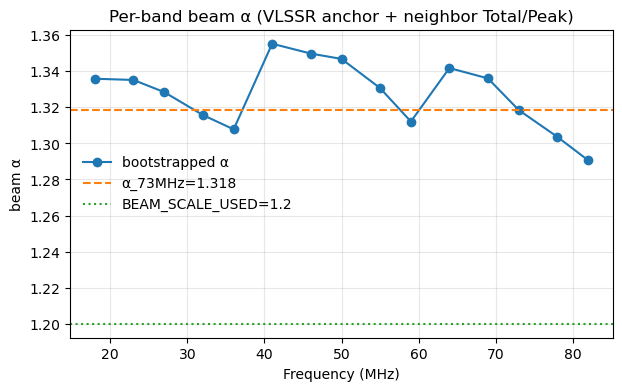

Wrote /fast/claw/metacatalog_healpix_IdTR-0.75s_subband2/beam_alpha_by_band.parquet
Wrote /fast/claw/metacatalog_healpix_IdTR-0.75s_subband2/beam_alpha_by_band_steps.parquet
load_beam_alpha_mapping OK (15 bands)


In [3]:
from lwa_catalog.analyze import (
    lwa_bands_with_total_flux,
    median_neighbor_flux_ratio,
    unconfused_unique_mask,
)

# --- VLSSR anchor: Total_73 vs Peak_VLSSR (unique) ---
total_anchor_col = f"Total_flux_{ANCHOR_BAND}"
if (
    "Peak_flux_VLSSR" in meta.columns
    and total_anchor_col in meta.columns
):
    t_anch = pd.to_numeric(meta[total_anchor_col], errors="coerce")
    v_pk = pd.to_numeric(meta["Peak_flux_VLSSR"], errors="coerce")
    ok_v = (t_anch > 0) & (v_pk > 0)
    if "n_assoc_VLSSR" in meta.columns:
        n_assoc = pd.to_numeric(meta["n_assoc_VLSSR"], errors="coerce")
        ok_v = ok_v & (n_assoc == 1)
    x_v = np.log10(v_pk.loc[ok_v].to_numpy(dtype=float))
    y_v = np.log10(t_anch.loc[ok_v].to_numpy(dtype=float))
    fig_v, ax_v = plt.subplots(figsize=(6, 5))
    ax_v.scatter(x_v, y_v, s=8, alpha=0.2, c="C0", rasterized=True)
    lim_v = [
        min(float(np.min(x_v)), float(np.min(y_v))),
        max(float(np.max(x_v)), float(np.max(y_v))),
    ]
    pad_v = 0.05 * (lim_v[1] - lim_v[0] if lim_v[1] > lim_v[0] else 1.0)
    lim_v = [lim_v[0] - pad_v, lim_v[1] + pad_v]
    ax_v.plot(lim_v, lim_v, "k--", lw=1)
    ax_v.set_xlim(lim_v)
    ax_v.set_ylim(lim_v)
    ax_v.set_aspect("equal", adjustable="box")
    ax_v.set_xlabel("log10 Peak_flux_VLSSR (Jy)")
    ax_v.set_ylabel(f"log10 {total_anchor_col} (Jy)")
    ax_v.set_title(
        f"VLSSR anchor ({ok_v.sum():,} unique)  "
        f"med T/VLSSR={result.median_total_over_vlssr:.3f}  "
        f"corr={result.alpha_correction:.3f}  "
        f"α_true={result.beam_scale_used:g}×corr={result.alpha_anchor:.3f}"
    )
    plt.show()
else:
    print("Skipping VLSSR flux–flux (missing Peak_flux_VLSSR or Total anchor column)")

# --- Neighbor Total_flux–Total_flux (unconfused unique) ---
lwa_ff_bands = lwa_bands_with_total_flux(meta)
neighbor_pairs = list(zip(lwa_ff_bands[:-1], lwa_ff_bands[1:]))
print(f"LWA bands with Total_flux ({len(lwa_ff_bands)}): {lwa_ff_bands}")
print(f"Neighbor pairs: {len(neighbor_pairs)}")

if neighbor_pairs:
    n_pairs = len(neighbor_pairs)
    ncols = min(3, n_pairs)
    nrows = int(np.ceil(n_pairs / ncols))
    fig_ff, axes = plt.subplots(
        nrows, ncols, figsize=(4.2 * ncols, 4.0 * nrows), squeeze=False
    )
    summary_rows: list[dict] = []
    for i, (band_lo, band_hi) in enumerate(neighbor_pairs):
        ax = axes[i // ncols][i % ncols]
        mask = unconfused_unique_mask(meta, band_lo) & unconfused_unique_mask(
            meta, band_hi
        )
        x = pd.to_numeric(meta[f"Total_flux_{band_lo}"], errors="coerce")
        y = pd.to_numeric(meta[f"Total_flux_{band_hi}"], errors="coerce")
        ok = mask & (x > 0) & (y > 0)
        x_ok = np.log10(x.loc[ok].to_numpy(dtype=float))
        y_ok = np.log10(y.loc[ok].to_numpy(dtype=float))
        n = int(ok.sum())
        med_t, _ = median_neighbor_flux_ratio(
            meta, band_lo, band_hi, flux_prefix="Total_flux"
        )
        if n:
            log_ratio = y_ok - x_ok
            med_log = float(np.median(log_ratio))
            ax.scatter(x_ok, y_ok, s=6, alpha=0.15, c="C0", rasterized=True)
            lim = [
                min(float(np.min(x_ok)), float(np.min(y_ok))),
                max(float(np.max(x_ok)), float(np.max(y_ok))),
            ]
            pad = 0.05 * (lim[1] - lim[0] if lim[1] > lim[0] else 1.0)
            lim = [lim[0] - pad, lim[1] + pad]
            ax.plot(lim, lim, "k--", lw=1)
            ax.set_xlim(lim)
            ax.set_ylim(lim)
        else:
            med_log = float("nan")
            ax.text(
                0.5, 0.5, "no pairs", ha="center", va="center", transform=ax.transAxes
            )
        ax.set_xlabel(f"log10 Total_flux_{band_lo} (Jy)")
        ax.set_ylabel(f"log10 Total_flux_{band_hi} (Jy)")
        ax.set_title(
            f"{band_lo} → {band_hi}\nn={n:,}"
            + (f", med log10 ratio={med_log:+.3f}" if np.isfinite(med_log) else "")
        )
        ax.set_aspect("equal", adjustable="box")
        summary_rows.append(
            {
                "band_lo": band_lo,
                "band_hi": band_hi,
                "n_unconfused_unique": n,
                "median_T_hi_over_lo": med_t,
                "median_log10_hi_over_lo": med_log,
            }
        )
    for j in range(n_pairs, nrows * ncols):
        axes[j // ncols][j % ncols].set_visible(False)
    fig_ff.suptitle(
        "LWA neighbor Total_flux–Total_flux (n_assoc=1 & n_confused=1)",
        y=1.01,
    )
    fig_ff.tight_layout()
    plt.show()
    lwa_neighbor_flux_summary = pd.DataFrame(summary_rows)
    print(lwa_neighbor_flux_summary.to_string(index=False))
else:
    print("No neighboring LWA band pairs to plot.")

# --- Per-band α vs frequency ---
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(
    result.by_band["nu_mhz"],
    result.by_band["alpha"],
    "o-",
    color="C0",
    label="bootstrapped α",
)
ax.axhline(
    result.alpha_anchor,
    color="C1",
    ls="--",
    label=f"α_{ANCHOR_BAND}={result.alpha_anchor:.3f}",
)
ax.axhline(
    BEAM_SCALE_USED,
    color="C2",
    ls=":",
    label=f"BEAM_SCALE_USED={BEAM_SCALE_USED}",
)
ax.set_xlabel("Frequency (MHz)")
ax.set_ylabel("beam α")
ax.set_title("Per-band beam α (VLSSR anchor + neighbor Total/Peak)")
ax.legend(frameon=False)
ax.grid(True, alpha=0.3)
plt.show()

if WRITE_OUTPUT:
    out = write_beam_alpha_table(result, layout)
    print(f"Wrote {out.resolve()}")
    steps_path = out.with_name(out.stem + "_steps.parquet")
    if steps_path.is_file():
        print(f"Wrote {steps_path.resolve()}")
    json_path = layout.beam_scale_json()
    print(f"Wrote {json_path.resolve()}  (BEAM_SCALE mapping + VLSSR anchor metadata)")
    # Round-trip check for detect notebook loader
    loaded = load_beam_alpha_mapping(layout)
    assert loaded == beam_alpha_mapping
    print(f"load_beam_alpha_mapping OK ({len(loaded)} bands)")
else:
    print("WRITE_OUTPUT=False — skipped parquet/json write")


## Re-detect checklist

1. Point `ovro_lwa_healpix_tile_detect.ipynb` `OUTPUT_DIR` at a **new** tree (or clear tile caches).
2. Set `ESTIMATE_BEAM_SCALE = False`.
3. Either:
   - `BEAM_SCALE_TABLE = Path(".../beam_scale.json")` (preferred; same tree as Parquets), or
   - `BEAM_SCALE = load_beam_alpha_mapping(CatalogLayout(PRIOR_TREE))`, or
   - paste the printed dict as `BEAM_SCALE = {...}`.
4. Re-run tile detect → tile merge → fusion → reliability → radio crossmatch.
5. Re-run this notebook on the new tree with `BEAM_SCALE_USED` equal to the
   per-band (or scalar) α actually used in that re-detect — required so the
   VLSSR correction multiplies the right prior. Expect `alpha_correction ≈ 1`
   and neighbor `alpha_hi_over_lo ≈ 1` if Totals are photometrically consistent.
